# TP N°3 : Analyse d'image — Opérations et primitives
Vision Artificielle

## 0. Imports, paramètres et fonctions utiles

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

PATH_IMAGE_1 = "arbre.jpeg"
PATH_IMAGE_2 = "image2.jpg"  
PATH_IMAGE_3 = "image3.jpg"  
OUT = "resultats"
os.makedirs(OUT, exist_ok=True)

def save(name, image):
    cv2.imwrite(os.path.join(OUT, name), image)

def show(images, titles=None, cols=3, size=4):
    """Affiche une liste d'images (BGR ou niveaux de gris) avec matplotlib."""
    rows = (len(images) + cols - 1) // cols
    plt.figure(figsize=(size * cols, size * rows))
    for i, im in enumerate(images):
        plt.subplot(rows, cols, i + 1)
        if im.ndim == 2:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        else:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        if titles:
            plt.title(titles[i], fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## Exploration de l'image (code de l'énoncé)

height = 480 | width = 640 | canaux = 3
pixel (20,10) = [ 89 107  94]


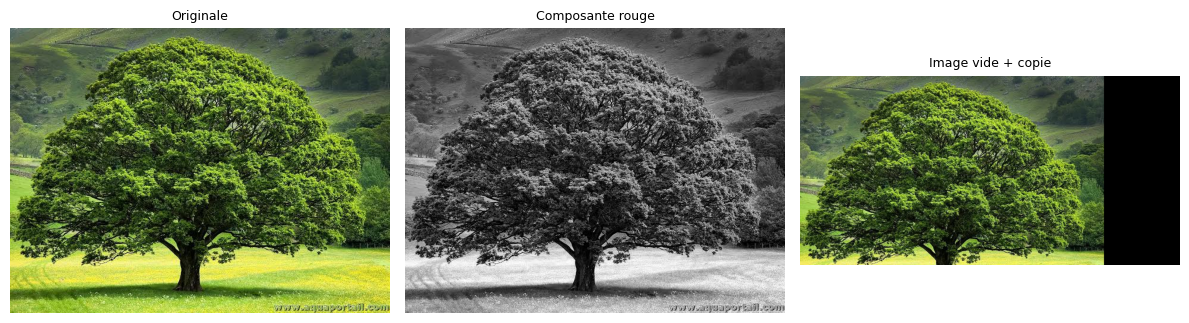

In [2]:
img = cv2.imread(PATH_IMAGE_1)
assert img is not None, f"Impossible de lire {PATH_IMAGE_1}"

height, width = img.shape[:2]
print("height =", height, "| width =", width, "| canaux =", img.shape[2])

red = img[:, :, 2]                # composante rouge (OpenCV = BGR)
print("pixel (20,10) =", img[20, 10])

img2 = img.copy()                 # copie
img2[50, 80] = [0, 255, 255]      # pixel modifié (jaune)

img_empty = np.zeros((400, 800, 3), np.uint8)       # image vide
h_c, w_c = min(400, height), min(800, width)
img_empty[0:h_c, 0:w_c] = img[0:h_c, 0:w_c]         # copie dans l'image vide
save("00_image_vide_copie.jpg", img_empty)

show([img, red, img_empty], ["Originale", "Composante rouge", "Image vide + copie"])

## 1. Transformation de l'image

### 1) Modification de la taille + sauvegarde

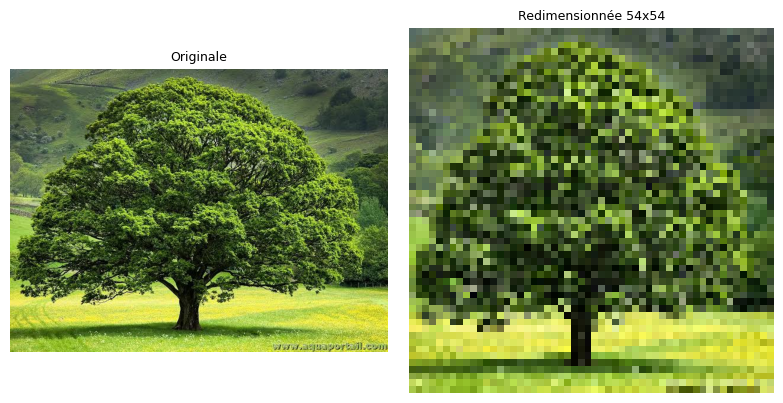

In [3]:
img_resized = cv2.resize(img, (54, 54))
save("01_resize_54x54.jpg", img_resized)
show([img, img_resized], ["Originale", "Redimensionnée 54x54"], cols=2)

### 2) et 3) Rotations des trois composantes + sauvegarde
> Le centre de rotation doit être `(largeur/2, hauteur/2)` = `(shape[1]/2, shape[0]/2)` (l'énoncé a inversé les deux).

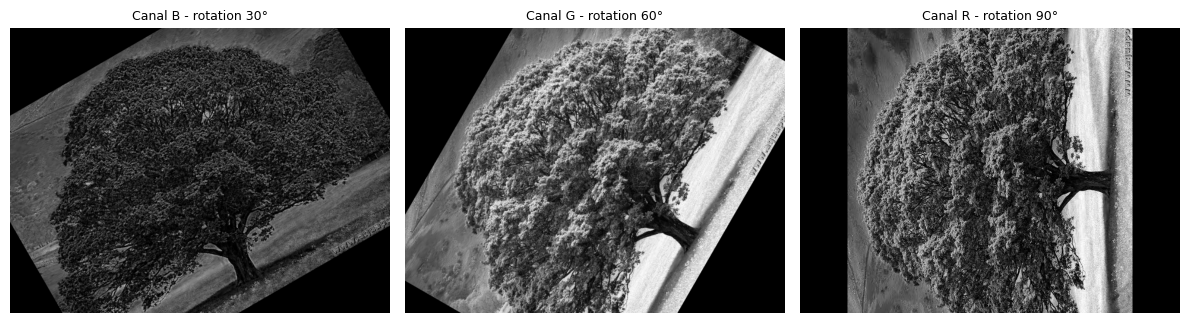

In [4]:
def rotate(image, deg):
    h, w = image.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), deg, 1)
    return cv2.warpAffine(image, M, (w, h))

b, g, r = cv2.split(img)
composantes = {"B": b, "G": g, "R": r}
angles = {"B": 30, "G": 60, "R": 90}

imgs, titres = [], []
for nom, comp in composantes.items():
    rot = rotate(comp, angles[nom])
    save(f"02_rotation_{nom}_{angles[nom]}deg.jpg", rot)
    imgs.append(rot); titres.append(f"Canal {nom} - rotation {angles[nom]}°")
show(imgs, titres)

### 4) et 5) Retournement des trois composantes + sauvegarde
> `flip(img, 0)` : retournement **vertical** (haut ↔ bas) ; `flip(img, 1)` : **horizontal** (gauche ↔ droite).

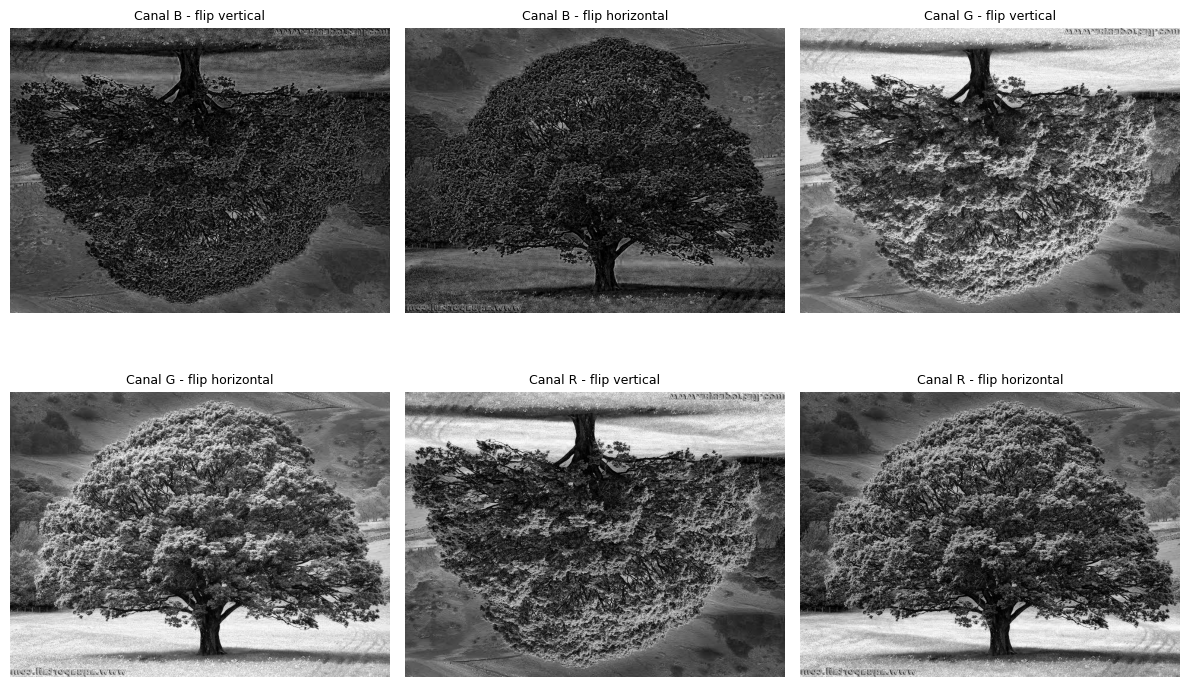

In [5]:
imgs, titres = [], []
for nom, comp in composantes.items():
    fv = cv2.flip(comp, 0)
    fh = cv2.flip(comp, 1)
    save(f"03_flip_{nom}_vertical.jpg", fv)
    save(f"03_flip_{nom}_horizontal.jpg", fh)
    imgs += [fv, fh]
    titres += [f"Canal {nom} - flip vertical", f"Canal {nom} - flip horizontal"]
show(imgs, titres)

### 6), 7) et 8) Découpage en sous-images, redimensionnement et cadrage

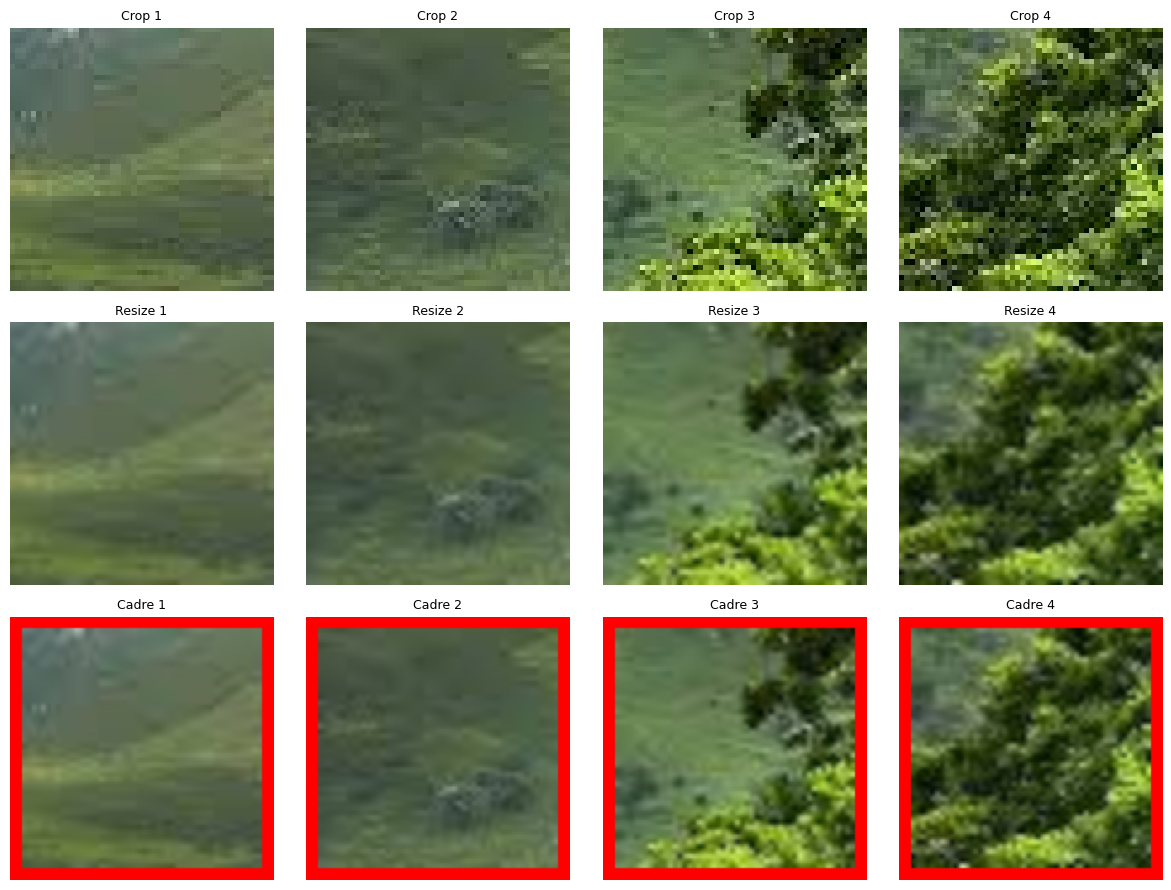

In [6]:
positions = [(0, 0), (50, 50), (100, 100), (150, 50)]   # (x, y)
crops, resized_l, framed_l = [], [], []

for i, (x, y) in enumerate(positions, start=1):
    cropped = img[y:y + 50, x:x + 50]           # [lignes(y), colonnes(x)]
    if cropped.shape[0] < 50 or cropped.shape[1] < 50:
        print(f"Sous-image {i} hors de l'image, ignorée")
        continue
    save(f"04_crop_{i}.jpg", cropped)                                   # 6)

    resized = cv2.resize(cropped, (100, 100))                           # 7)
    save(f"05_crop_{i}_resize100.jpg", resized)

    framed = cv2.copyMakeBorder(resized, 5, 5, 5, 5,                    # 8) cadre rouge
                                cv2.BORDER_CONSTANT, value=(0, 0, 255))
    save(f"06_crop_{i}_cadre.jpg", framed)

    crops.append(cropped); resized_l.append(resized); framed_l.append(framed)

n = len(crops)
show(crops + resized_l + framed_l,
     [f"Crop {i+1}" for i in range(n)] +
     [f"Resize {i+1}" for i in range(n)] +
     [f"Cadre {i+1}" for i in range(n)], cols=n, size=3)

## 2. Égalisation de contraste

### 1) Histogram equalization vs CLAHE

Contraste (écart-type) original     : 61.87
Contraste (écart-type) equalizeHist : 73.48
Contraste (écart-type) CLAHE        : 66.75
=> Image la plus contrastée : equalizeHist


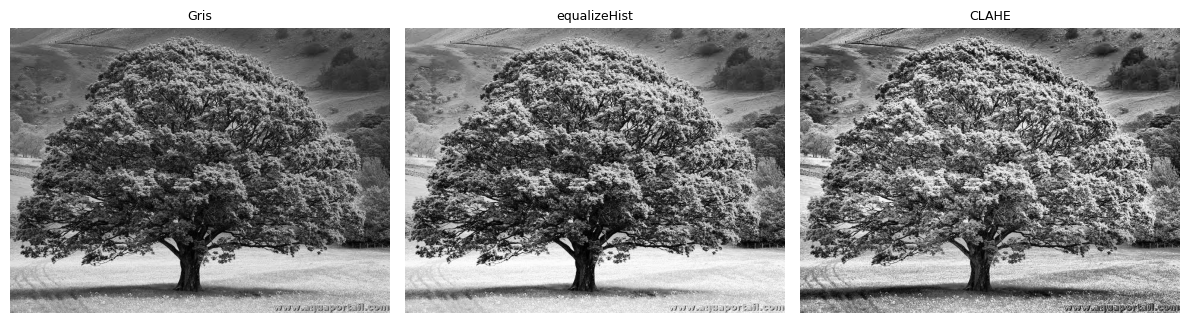

C:\Users\admin\AppData\Local\Temp\ipykernel_4216\2703061721.py:24: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(im.ravel(), 256, [0, 256]); plt.title("Histogramme - " + t)


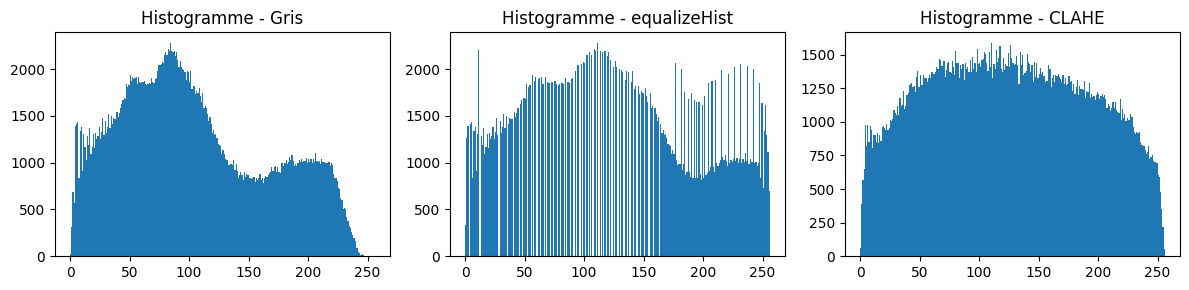

In [7]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

eq = cv2.equalizeHist(gray)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
cl1 = clahe.apply(gray)

save("10_gray.jpg", gray); save("11_equalizeHist.jpg", eq); save("12_clahe.jpg", cl1)

# Le contraste est mesuré par l'écart-type des niveaux de gris
contrastes = {"original": gray.std(), "equalizeHist": eq.std(), "CLAHE": cl1.std()}
for k, v in contrastes.items():
    print(f"Contraste (écart-type) {k:13s}: {v:.2f}")

meilleur_nom = "equalizeHist" if eq.std() >= cl1.std() else "CLAHE"
meilleure = eq if meilleur_nom == "equalizeHist" else cl1
print("=> Image la plus contrastée :", meilleur_nom)

show([gray, eq, cl1], ["Gris", "equalizeHist", "CLAHE"])

# Histogrammes
plt.figure(figsize=(12, 3))
for i, (im, t) in enumerate([(gray, "Gris"), (eq, "equalizeHist"), (cl1, "CLAHE")]):
    plt.subplot(1, 3, i + 1)
    plt.hist(im.ravel(), 256, [0, 256]); plt.title("Histogramme - " + t)
plt.tight_layout(); plt.show()

### 2) Seuillage de l'image la plus contrastée (deux méthodes)

Seuil d'Otsu calculé = 127.0


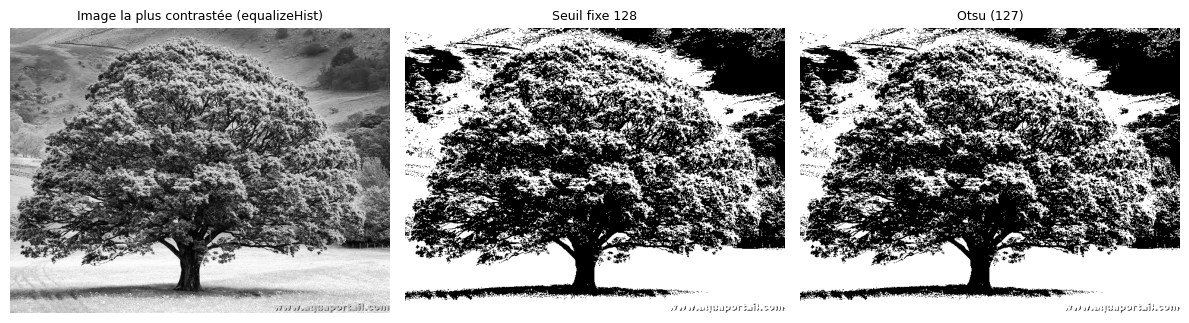

In [8]:
# Méthode A : seuil fixe = 128  (<128 -> 0, >=128 -> 255)
_, seuil_fixe = cv2.threshold(meilleure, 128, 255, cv2.THRESH_BINARY)

# Méthode B : seuil automatique d'Otsu
ret_otsu, seuil_otsu = cv2.threshold(meilleure, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Seuil d'Otsu calculé =", ret_otsu)

# Vérification manuelle de la méthode A avec NumPy
assert np.array_equal(seuil_fixe, np.where(meilleure < 128, 0, 255).astype(np.uint8))

save("13_seuil_fixe_128.jpg", seuil_fixe); save("14_seuil_otsu.jpg", seuil_otsu)
show([meilleure, seuil_fixe, seuil_otsu],
     [f"Image la plus contrastée ({meilleur_nom})", "Seuil fixe 128", f"Otsu ({ret_otsu:.0f})"])

## 3. Opérateurs morphologiques

Noyau rect :
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]



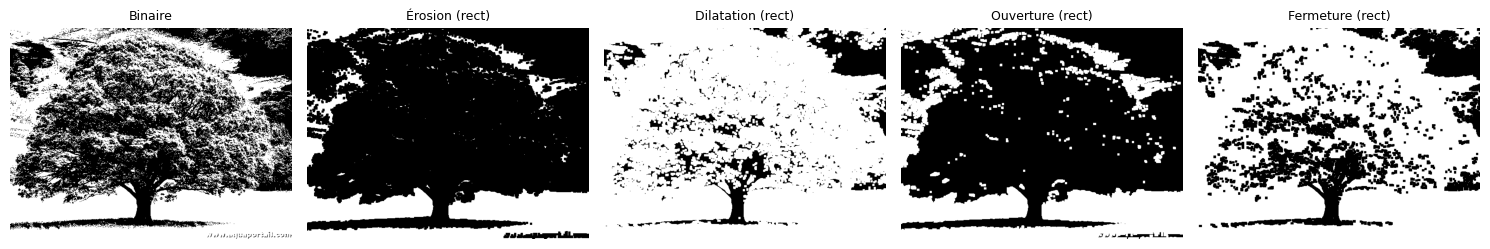

Noyau ellipse :
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]



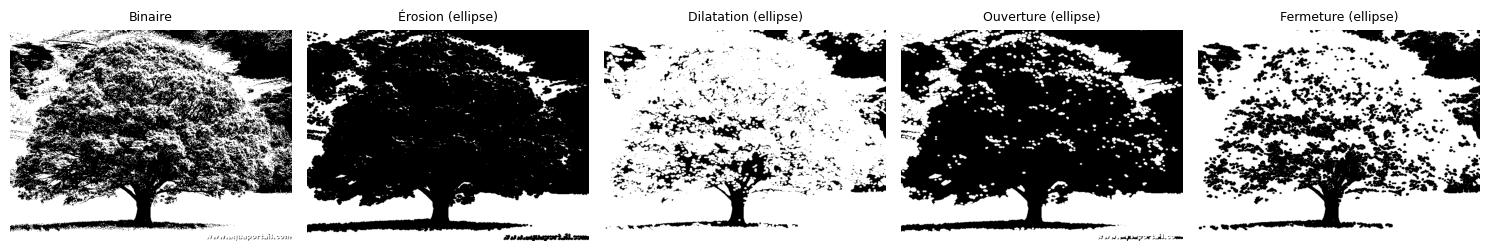

Noyau cross :
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]



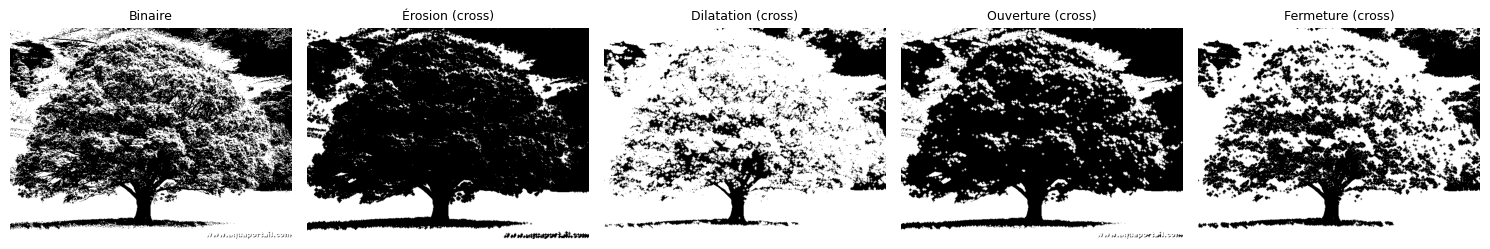

In [9]:
binaire = seuil_fixe

kernels = {
    "rect":    cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5)),
    "ellipse": cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)),
    "cross":   cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5)),
}

for nom, k in kernels.items():
    print(f"Noyau {nom} :\n{k}\n")
    erosion  = cv2.erode(binaire, k, iterations=1)
    dilation = cv2.dilate(binaire, k, iterations=1)
    opening  = cv2.morphologyEx(binaire, cv2.MORPH_OPEN, k)
    closing  = cv2.morphologyEx(binaire, cv2.MORPH_CLOSE, k)
    for tag, res in [("erosion", erosion), ("dilation", dilation),
                     ("opening", opening), ("closing", closing)]:
        save(f"20_{nom}_{tag}.jpg", res)
    show([binaire, erosion, dilation, opening, closing],
         ["Binaire", f"Érosion ({nom})", f"Dilatation ({nom})",
          f"Ouverture ({nom})", f"Fermeture ({nom})"], cols=5, size=3)

## 4. Addition et soustraction d'images

'image2.jpg' introuvable -> image de secours utilisée
'image3.jpg' introuvable -> image de secours utilisée


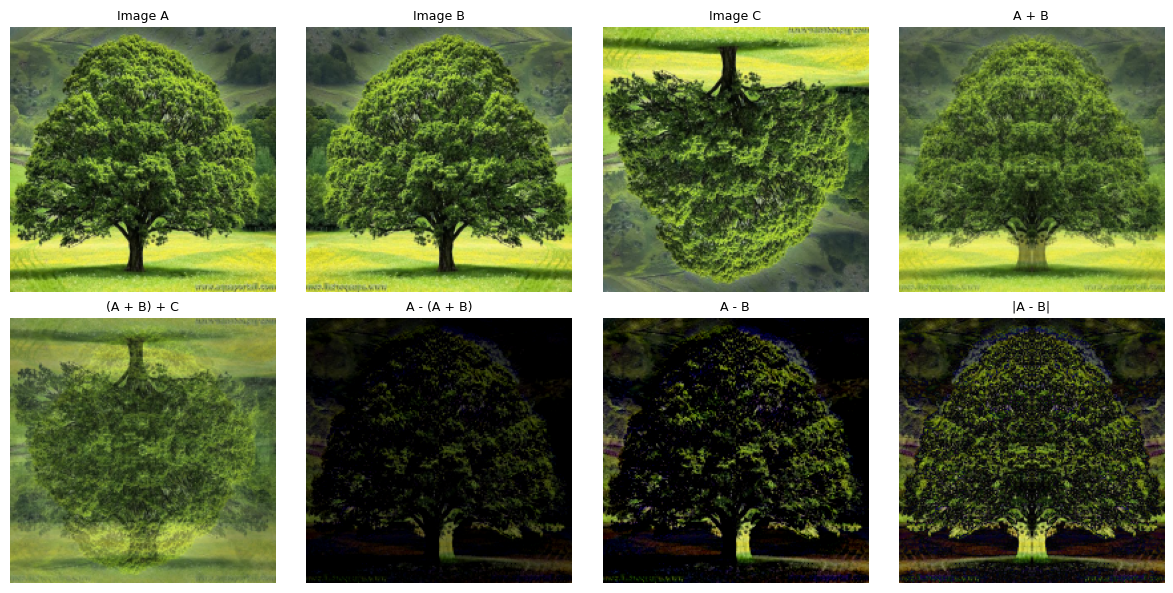

In [10]:
def load(path, fallback):
    im = cv2.imread(path)
    if im is None:
        print(f"'{path}' introuvable -> image de secours utilisée")
        return fallback
    return im

SIZE = (200, 200)
im_a = cv2.resize(img, SIZE, interpolation=cv2.INTER_AREA)
im_b = cv2.resize(load(PATH_IMAGE_2, cv2.flip(img, 1)), SIZE, interpolation=cv2.INTER_AREA)
im_c = cv2.resize(load(PATH_IMAGE_3, cv2.flip(img, 0)), SIZE, interpolation=cv2.INTER_AREA)

# 1) Image de sommation
somme1 = cv2.addWeighted(im_a, 0.5, im_b, 0.5, 0)
# 2) Deuxième addition avec une autre image
somme2 = cv2.addWeighted(somme1, 0.5, im_c, 0.5, 0)
# 3) Soustractions (cv2.subtract sature à 0)
sub_1 = cv2.subtract(im_a, somme1)
sub_2 = cv2.subtract(im_a, im_b)
sub_3 = cv2.absdiff(im_a, im_b)

for name, res in [("30_somme_a_b", somme1), ("31_somme_ab_c", somme2),
                  ("32_sub_a_somme1", sub_1), ("33_sub_a_b", sub_2), ("34_absdiff_a_b", sub_3)]:
    save(name + ".jpg", res)

show([im_a, im_b, im_c, somme1, somme2, sub_1, sub_2, sub_3],
     ["Image A", "Image B", "Image C", "A + B", "(A + B) + C",
      "A - (A + B)", "A - B", "|A - B|"], cols=4, size=3)